In [1]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

RAW_FILE = PROJECT_ROOT / "data" / "raw" / "interviewtestdataset.csv"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
DB_FILE = PROJECT_ROOT / "data" / "cosmetics.db"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("Raw file:", RAW_FILE)
print("Processed directory:", PROCESSED_DIR)

Raw file: c:\Users\thula\MY\casestudy\data\raw\interviewtestdataset.csv
Processed directory: c:\Users\thula\MY\casestudy\data\processed


####  Load Dataset

In [2]:
df = pd.read_csv(RAW_FILE, low_memory=False)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (114635, 22)

Columns:
['CDPHId', 'ProductName', 'CSFId', 'CSF', 'CompanyId', 'CompanyName', 'BrandName', 'PrimaryCategoryId', 'PrimaryCategory', 'SubCategoryId', 'SubCategory', 'CasId', 'CasNumber', 'ChemicalId', 'ChemicalName', 'InitialDateReported', 'MostRecentDateReported', 'DiscontinuedDate', 'ChemicalCreatedAt', 'ChemicalUpdatedAt', 'ChemicalDateRemoved', 'ChemicalCount']


,CDPHId,ProductName,CSFId,CSF,CompanyId,CompanyName,BrandName,PrimaryCategoryId,PrimaryCategory,SubCategoryId,...,CasNumber,ChemicalId,ChemicalName,InitialDateReported,MostRecentDateReported,DiscontinuedDate,ChemicalCreatedAt,ChemicalUpdatedAt,ChemicalDateRemoved,ChemicalCount
0,2,ULTRA COLOR RICH EXTRA PLUMP LIPSTICK-ALL SHADES,NaN,NaN,4,New Avon LLC,AVON,44,Makeup Products (non-permanent),53,...,13463-67-7,6,Titanium dioxide,06/17/2009,08/28/2013,02/01/2011,07/09/2009,07/09/2009,NaN,1
1,3,Glover's Medicated Shampoo,NaN,NaN,338,J. Strickland & Co.,Glover's,18,Hair Care Products (non-coloring),25,...,65996-92-1,4,Distillates (coal tar),07/01/2009,07/01/2009,NaN,07/01/2009,07/01/2009,NaN,2
2,3,Glover's Medicated Shampoo,NaN,NaN,338,J. Strickland & Co.,Glover's,18,Hair Care Products (non-coloring),25,...,140-67-0,5,Estragole,07/01/2009,07/01/2009,NaN,07/02/2009,07/02/2009,NaN,2
3,4,PRECISION GLIMMER EYE LINER-ALL SHADES �,NaN,NaN,4,New Avon LLC,AVON,44,Makeup Products (non-permanent),46,...,13463-67-7,7,Titanium dioxide,07/09/2009,08/28/2013,NaN,07/09/2009,07/09/2009,NaN,1
4,5,AVON BRILLIANT SHINE LIP GLOSS-ALL SHADES �,NaN,NaN,4,New Avon LLC,AVON,44,Makeup Products (non-permanent),52,...,13463-67-7,8,Titanium dioxide,07/09/2009,08/28/2013,02/01/2011,07/09/2009,07/09/2009,NaN,1


#### Dataset overview

In [3]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nUnique products:", df["CDPHId"].nunique())
print("Unique companies:", df["CompanyName"].nunique())
print("Unique brands:", df["BrandName"].nunique())
print("Unique chemicals:", df["ChemicalName"].nunique())
print("Unique CAS numbers:", df["CasNumber"].nunique())

Rows: 114635
Columns: 22

Data types:


,Data Type
CDPHId,int64
ProductName,str
CSFId,float64
CSF,str
CompanyId,int64
CompanyName,str
BrandName,str
PrimaryCategoryId,int64
PrimaryCategory,str
SubCategoryId,int64



Unique products: 36972
Unique companies: 606
Unique brands: 2713
Unique chemicals: 123
Unique CAS numbers: 125


#### Missing value analysis

In [4]:
missing_analysis = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

missing_analysis = missing_analysis.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing_analysis)

,Missing Count,Missing Percentage
ChemicalDateRemoved,111650,97.40
DiscontinuedDate,101715,88.73
CSF,34398,30.01
CSFId,33973,29.64
CasNumber,6476,5.65
BrandName,227,0.20
CompanyName,0,0.00
CompanyId,0,0.00
CDPHId,0,0.00
ProductName,0,0.00


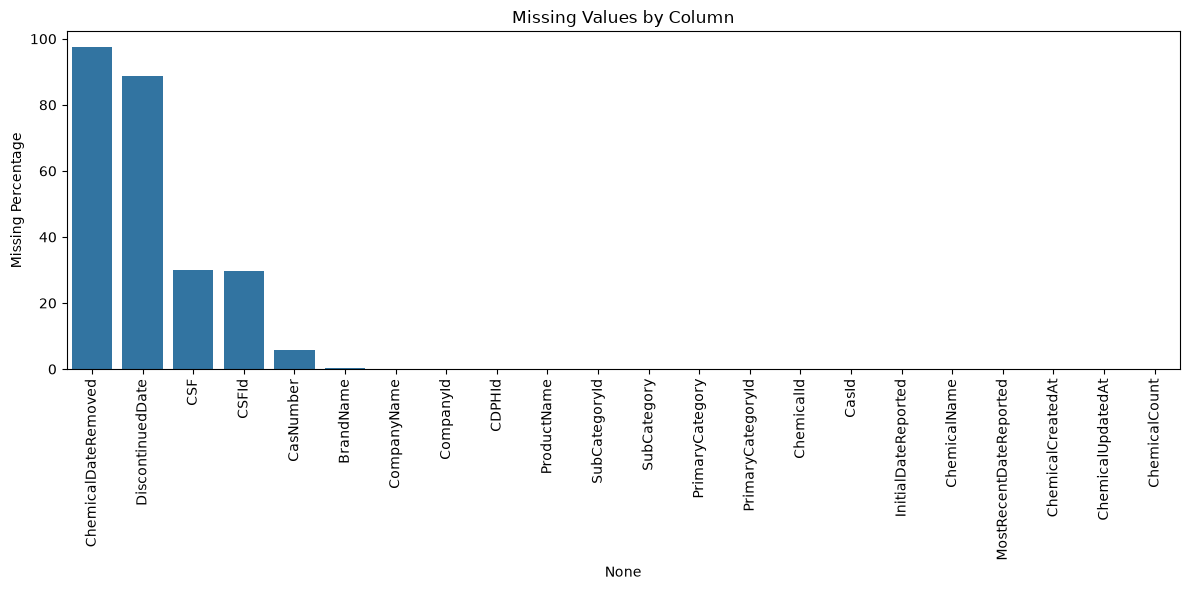

In [5]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=missing_analysis.index,
    y=missing_analysis["Missing Percentage"]
)

plt.xticks(rotation=90)
plt.ylabel("Missing Percentage")
plt.title("Missing Values by Column")
plt.tight_layout()
plt.show()

#### Duplicate analysis

In [6]:
exact_duplicates = df.duplicated().sum()

print("Exact duplicate rows:", exact_duplicates)

# Products can have multiple chemicals.
# Therefore, CDPHId alone is NOT a duplicate key.

product_chemical_duplicates = df.duplicated(
    subset=["CDPHId", "ChemicalId"]
).sum()

print("Duplicate product-chemical combinations:",
      product_chemical_duplicates)

Exact duplicate rows: 254
Duplicate product-chemical combinations: 56035


#### Clean string columns

In [7]:
cleaned_df = df.copy()

string_columns = cleaned_df.select_dtypes(
    include=["object"]
).columns

for col in string_columns:
    cleaned_df[col] = cleaned_df[col].str.strip()
    cleaned_df[col] = cleaned_df[col].replace("", pd.NA)

print("String columns cleaned.")

String columns cleaned.


C:\Users\thula\AppData\Local\Temp\ipykernel_47364\299563628.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  string_columns = cleaned_df.select_dtypes(


#### Normalize date columns

In [8]:
date_columns = [
    "InitialDateReported",
    "MostRecentDateReported",
    "DiscontinuedDate",
    "ChemicalCreatedAt",
    "ChemicalUpdatedAt",
    "ChemicalDateRemoved"
]

for col in date_columns:
    cleaned_df[col] = pd.to_datetime(
        cleaned_df[col],
        format="%m/%d/%Y",
        errors="coerce"
    )

print("Date columns converted.")

display(cleaned_df[date_columns].head())

Date columns converted.


,InitialDateReported,MostRecentDateReported,DiscontinuedDate,ChemicalCreatedAt,ChemicalUpdatedAt,ChemicalDateRemoved
0,2009-06-17,2013-08-28,2011-02-01,2009-07-09,2009-07-09,NaT
1,2009-07-01,2009-07-01,NaT,2009-07-01,2009-07-01,NaT
2,2009-07-01,2009-07-01,NaT,2009-07-02,2009-07-02,NaT
3,2009-07-09,2013-08-28,NaT,2009-07-09,2009-07-09,NaT
4,2009-07-09,2013-08-28,2011-02-01,2009-07-09,2009-07-09,NaT


#### Validate data

In [9]:
# Check missing identifiers
print("Missing Product IDs:", cleaned_df["CDPHId"].isna().sum())
print("Missing Chemical IDs:", cleaned_df["ChemicalId"].isna().sum())

# Check missing chemical names
print("Missing Chemical Names:",
      cleaned_df["ChemicalName"].isna().sum())

# Check invalid date values
for col in date_columns:
    print(
        col,
        "Missing/invalid:",
        cleaned_df[col].isna().sum()
    )

Missing Product IDs: 0
Missing Chemical IDs: 0
Missing Chemical Names: 0
InitialDateReported Missing/invalid: 0
MostRecentDateReported Missing/invalid: 0
DiscontinuedDate Missing/invalid: 101715
ChemicalCreatedAt Missing/invalid: 0
ChemicalUpdatedAt Missing/invalid: 0
ChemicalDateRemoved Missing/invalid: 111650


### Save cleaned dataset

In [10]:
CLEANED_FILE = PROCESSED_DIR / "cosmetics_cleaned.csv"

cleaned_df.to_csv(
    CLEANED_FILE,
    index=False,
    date_format="%Y-%m-%d"
)

print("Cleaned dataset saved:", CLEANED_FILE)

Cleaned dataset saved: c:\Users\thula\MY\casestudy\data\processed\cosmetics_cleaned.csv


#### Load cleaned data into SQLite

In [11]:
connection = sqlite3.connect(DB_FILE)

cleaned_df.to_sql(
    "cosmetics",
    connection,
    if_exists="replace",
    index=False
)

# Create indexes for frequently filtered columns
indexes = [
    "CREATE INDEX IF NOT EXISTS idx_product_id ON cosmetics(CDPHId)",
    "CREATE INDEX IF NOT EXISTS idx_chemical_name ON cosmetics(ChemicalName)",
    "CREATE INDEX IF NOT EXISTS idx_cas_number ON cosmetics(CasNumber)",
    "CREATE INDEX IF NOT EXISTS idx_company_name ON cosmetics(CompanyName)",
    "CREATE INDEX IF NOT EXISTS idx_brand_name ON cosmetics(BrandName)",
    "CREATE INDEX IF NOT EXISTS idx_category ON cosmetics(PrimaryCategory)",
    "CREATE INDEX IF NOT EXISTS idx_subcategory ON cosmetics(SubCategory)"
]

for index_query in indexes:
    connection.execute(index_query)

connection.commit()

print("SQLite database created:", DB_FILE)

SQLite database created: c:\Users\thula\MY\casestudy\data\cosmetics.db


#### Verify SQLite data

In [12]:
query = """
SELECT
    COUNT(*) AS total_rows,
    COUNT(DISTINCT CDPHId) AS unique_products,
    COUNT(DISTINCT ChemicalId) AS unique_chemicals,
    COUNT(DISTINCT CompanyId) AS unique_companies
FROM cosmetics;
"""

verification_df = pd.read_sql_query(query, connection)

display(verification_df)

,total_rows,unique_products,unique_chemicals,unique_companies
0,114635,36972,58079,635
